# 03 – Prediction order sensitivity: f(A, B) versus f(B, A)
**Reproduces:** Section 5.5, Table 10 (per-fold order sensitivity) and Figure 3 (scatter of f(A, B) against f(B, A))
**Responds to:** Reviewer 2 Comment 3

Drug synergy should not depend on which drug is listed first, but the trained network is **not** permutation-invariant: the fusion stage concatenates
the streams in a fixed order. This notebook quantifies the discrepancy. Every trained fold model of the main experiment (notebook 01) is evaluated on the
held-out test records of its fold twice, with the drugs in the original order, f(A, B), and in reversed order, f(B, A) (152,223 test evaluations in total).
We report the correlation between the two predictions, their mean absolute difference (standardized units), and the PCC of the original order, of the
reversed order and of the order-averaged predictor ŷ_sym = ½ (f(A, B) + f(B, A)), which is exactly order-invariant by construction.
No model is trained or modified here. The cross-dataset order sensitivity is part of the cross-dataset notebook.

**How to run:** `Runtime → Run all`. Choose what the notebook does with `MODE` (Cell 2):

| `MODE` | What it does | Needs |
|---|---|---|
| `"show_reported"` | prints Table 10 and draws Figure 3 from our saved results (seconds) | `results/order_sensitivity_summary.csv`, `predictions/order_sensitivity/` (and `results/kfold_results_summary.csv` for the consistency check) |
| `"evaluate_saved"` (default) | loads our five trained fold models from `checkpoints/cold_drug/` and recomputes everything; no training, a CPU runtime is enough | data, checkpoints |

Each fold is saved to Drive as soon as it is finished and finished folds are skipped when the notebook is run again, so a disconnected session loses at most the fold in progress.
If you retrained the main experiment (notebook 01, `MODE = "train_and_evaluate"`), set `MODEL_SOURCE = "retrained"` in Cell 2 to analyse your own fold models.

> **Note.** This notebook only runs inference, so with our checkpoints it reproduces the reported numbers up to floating-point differences between
> hardware and library versions (about 1e-3 or less). If you analyse retrained models (`MODEL_SOURCE = "retrained"`), the numbers will deviate somewhat from
> the manuscript, because retraining is not exactly reproducible (single run per fold, non-deterministic GPU operations); the qualitative picture
> (moderate correlation between the two orders, reversed order less accurate) is what to compare.

**Reading the output:** lines ending in "(paper: ...)" show the value reported in the manuscript next to the value computed here.

In [ ]:
# ===== Cell 1: Environment =====
# Colab only. The package versions used for the reported results are pinned in requirements.txt.
!pip install -q rdkit matplotlib pubchempy torch torchvision torchaudio torch-geometric transformers xgboost

# Standard library
import json, os, sys
from pathlib import Path

# Numerics and data
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, ttest_rel

# Deep learning
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import Dataset

# Graph learning
from torch_geometric.data import Data, Batch
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GATv2Conv
from torch_geometric.nn.aggr import AttentionalAggregation
from torch_geometric.utils import to_dense_batch

# Chemistry
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem

# Pretrained chemical language model (ChemBERTa)
from transformers import AutoTokenizer, AutoModel

# Classical ML and metrics
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import average_precision_score, mean_squared_error, roc_auc_score
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

RDLogger.DisableLog("rdApp.*")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.1/38.1 MB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 28.7 MB/s eta 0:00:00


In [ ]:
# ===== Cell 2: Configuration =====
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not os.path.ismount("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")

# Project folder (see README): on Colab, upload the DualGATSynergy folder to your Drive or change this path.
ROOT = Path("/content/drive/MyDrive/DualGATSynergy") if IN_COLAB else Path(".")
DATA_DIR = ROOT / "data"

# --- Run mode (used in Cells 4-13) ---
MODE = "evaluate_saved"          # "show_reported": print Table 10 and draw Figure 3 from our saved results (no data, no GPU, seconds)
                                 # "evaluate_saved": load the trained fold models and recompute (no training; CPU is fine)
assert MODE in ("show_reported", "evaluate_saved"), f"unknown MODE: {MODE}"
RUN_HEAVY = MODE != "show_reported"   # Cells 4-13 run only when the data are needed

MODEL_SOURCE = "shipped"         # "shipped": our fold models (checkpoints/cold_drug/)
                                 # "retrained": models written by notebook 01 in train_and_evaluate mode (checkpoints_retrained/cold_drug/)
assert MODEL_SOURCE in ("shipped", "retrained"), f"unknown MODEL_SOURCE: {MODEL_SOURCE}"
FOLDS_TO_RUN = [1, 2, 3, 4, 5]

if MODEL_SOURCE == "shipped":
    CKPT_DIR     = ROOT / "checkpoints" / "cold_drug"
    MAIN_RESULTS = ROOT / "results" / "kfold_results_summary.csv"            # notebook 01, our models
    RUN_DIR      = ROOT / "results_reproduced" / "order_sensitivity"
else:
    CKPT_DIR     = ROOT / "checkpoints_retrained" / "cold_drug"
    MAIN_RESULTS = ROOT / "results_retrained" / "kfold_results_summary.csv"  # notebook 01, retrained models
    RUN_DIR      = ROOT / "results_retrained" / "order_sensitivity"
RESULTS_SHIPPED = ROOT / "results" / "order_sensitivity_summary.csv"         # the reported per-fold table (Table 10)
PRED_SHIPPED    = ROOT / "predictions" / "order_sensitivity"                 # reported raw predictions, one file per fold (Figure 3)

SEED = 42
torch.manual_seed(SEED)   # also seeds CUDA (inference only; no randomness is used)
np.random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Mode: {MODE} | models: {MODEL_SOURCE} | device: {DEVICE} | project folder: {ROOT}")

Mode: evaluate_saved | models: shipped | device: cpu | project folder: /content/drive/MyDrive/DualGATSynergy


## Table 10 and Figure 3 from the saved results (no data or GPU needed)

In [ ]:
# ===== Cell 3: Table 10 and Figure 3 =====
import matplotlib.pyplot as plt

PAPER_TABLE7 = {   # per fold (folds 1-5), as reported in Table 10 (3 decimals)
    "order_corr":      [0.639, 0.571, 0.628, 0.775, 0.704],
    "pcc_forward":     [0.259, 0.428, 0.415, 0.300, 0.328],
    "pcc_reversed":    [0.184, 0.309, 0.321, 0.261, 0.243],
    "pcc_symmetrized": [0.245, 0.419, 0.411, 0.298, 0.312]}
PAPER_MEANS = {"order_corr": 0.663, "pcc_forward": 0.346, "pcc_reversed": 0.263, "pcc_symmetrized": 0.337}
PAPER_N_EVALUATIONS = 152_223
COLUMN_LABELS = {"order_corr": "r(f(A,B), f(B,A))", "pcc_forward": "PCC original order",
                 "pcc_reversed": "PCC reversed order", "pcc_symmetrized": "PCC order-averaged"}

def summarize_order_sensitivity(df, main=None):
    """Table 10 (per fold and mean) from a table with one row per fold."""
    df = df.sort_values("fold").reset_index(drop=True)
    shown = ["fold", "n_pairs", "order_corr", "mean_abs_diff", "pcc_forward", "pcc_reversed", "pcc_symmetrized",
             "rmse_forward", "rmse_reversed", "rmse_symmetrized"]
    print(df[shown].round(4).to_string(index=False))
    n = len(df)
    print(f"\nTest evaluations: {int(df['n_pairs'].sum()):,}" + (f"   (paper: {PAPER_N_EVALUATIONS:,})" if n == 5 else ""))
    for col, label in COLUMN_LABELS.items():
        print(f"Mean {label:20s}: {df[col].mean():.3f}" + (f"   (paper: {PAPER_MEANS[col]:.3f})" if n == 5 else ""))
    print(f"Mean absolute difference |f(A,B) - f(B,A)|, standardized units: {df['mean_abs_diff'].mean():.3f}")
    print(f"Reversed order less accurate in {(df['pcc_reversed'] < df['pcc_forward']).sum()}/{n} folds (PCC) "
          f"and {(df['rmse_reversed'] > df['rmse_forward']).sum()}/{n} folds (RMSE)")
    print(f"Order-averaged minus original-order mean PCC: {df['pcc_symmetrized'].mean() - df['pcc_forward'].mean():+.3f}")
    if n == 5:
        ok = all(np.allclose(df[c].values, PAPER_TABLE7[c], atol=1.5e-3) for c in PAPER_TABLE7)
        print("✓ per-fold values agree with Table 10 (to the 3 decimals shown there)" if ok else
              "⚠ some per-fold values differ from Table 10 by more than rounding")
    if main is not None:   # the original-order PCC must be exactly the main experiment's test PCC
        m = df.merge(main[["fold", "test_pcc"]], on="fold")
        assert np.allclose(m["pcc_forward"], m["test_pcc"], atol=1e-3), "original-order PCC differs from the main experiment"
        print("✓ original-order PCC equals the test PCC of the main experiment (notebook 01) in every fold")

def plot_order_sensitivity(npz_paths, out_png=None):
    """Figure 3: f(A,B) against f(B,A) for all test records of the given folds."""
    fwd, rev = [], []
    for p in npz_paths:
        d = np.load(p)
        fwd.append(d["preds_fwd"]); rev.append(d["preds_rev"])
    fwd, rev = np.concatenate(fwd), np.concatenate(rev)
    r = pearsonr(fwd, rev)[0]
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.scatter(fwd, rev, alpha=0.15, s=6, rasterized=True)
    lims = [min(fwd.min(), rev.min()), max(fwd.max(), rev.max())]
    ax.plot(lims, lims, "r--", linewidth=1.5, label="y = x (identical predictions)")
    ax.set_xlabel("Predicted synergy f(Drug A, Drug B)  [standardized]")
    ax.set_ylabel("Predicted synergy f(Drug B, Drug A)  [standardized]")
    ax.set_title(f"Prediction order sensitivity, all test records (r = {r:.3f}, n = {len(fwd):,})")
    ax.legend()
    fig.tight_layout()
    if out_png is not None:
        fig.savefig(out_png, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Pooled correlation over {len(fwd):,} test evaluations: r = {r:.3f}")

if RESULTS_SHIPPED.exists():
    reported = pd.read_csv(RESULTS_SHIPPED)
    reported_main = pd.read_csv(ROOT / "results" / "kfold_results_summary.csv") if (ROOT / "results" / "kfold_results_summary.csv").exists() else None
    summarize_order_sensitivity(reported, reported_main)
    if not RUN_HEAVY:
        files = [PRED_SHIPPED / f"order_sensitivity_fold{k}.npz" for k in range(1, 6)]
        if all(p.exists() for p in files):
            RUN_DIR.mkdir(parents=True, exist_ok=True)
            plot_order_sensitivity(files, out_png=RUN_DIR / "order_sensitivity_all_folds.png")   # 300 dpi PNG for the manuscript figure
        else:
            print(f"\nFigure 3 skipped: raw predictions not found in {PRED_SHIPPED}")
else:
    print(f"{RESULTS_SHIPPED} not found: place the reported results there to print Table 10.")
if not RUN_HEAVY:
    print("\nMODE = 'show_reported': nothing else to run. Set MODE = 'evaluate_saved' (Cell 2) to recompute with the trained models.")

 fold  n_pairs  order_corr  mean_abs_diff  pcc_forward  pcc_reversed  pcc_symmetrized  rmse_forward  rmse_reversed  rmse_symmetrized
    1    35446      0.6387         0.2221       0.2588        0.1840           0.2453        0.8706         0.8968            0.8694
    2    27418      0.5710         0.2551       0.4275        0.3089           0.4191        1.0554         1.1119            1.0673
    3    31635      0.6282         0.1910       0.4146        0.3211           0.4112        0.9423         0.9774            0.9497
    4    29840      0.7754         0.1805       0.2998        0.2605           0.2978        0.9349         0.9499            0.9328
    5    27884      0.7036         0.1795       0.3283        0.2426           0.3121        0.9204         0.9492            0.9256

Test evaluations: 152,223   (paper: 152,223)
Mean r(f(A,B), f(B,A))   : 0.663   (paper: 0.663)
Mean PCC original order  : 0.346   (paper: 0.346)
Mean PCC reversed order  : 0.263   (paper: 0.263)
Mean P

## Data, molecular representations and cold-drug partition (identical to notebook 01)

In [ ]:
# ===== Cell 4: Load and filter the raw data =====
if RUN_HEAVY:
    # --- 3.1 DrugComb v1.5 ---
    DRUGCOMB_COLS = ["drug_row", "drug_col", "cell_line_name", "synergy_hsa", "study_name", "tissue_name"]
    drugcomb_raw = pd.read_csv(DATA_DIR / "drugcomb_full_v1.5.csv", usecols=DRUGCOMB_COLS, low_memory=False)
    print(f"Raw records:                 {len(drugcomb_raw):,}   (paper: 1,432,351)")

    # Remove non-oncology studies
    NON_ONCOLOGY_KEYWORDS = ["malaria", "covid", "sars", "plasmodium", "tuberculosis"]
    is_non_oncology = (drugcomb_raw["study_name"].astype(str).str.lower()
                       .str.contains("|".join(NON_ONCOLOGY_KEYWORDS), na=False))
    drugcomb_raw = drugcomb_raw[~is_non_oncology].copy()

    # Drop records without an HSA score or a cell-line name (removes nothing in v1.5)
    drugcomb_raw = drugcomb_raw.dropna(subset=["synergy_hsa", "cell_line_name"])
    n_compounds = len(set(drugcomb_raw["drug_row"]) | set(drugcomb_raw["drug_col"]))
    print(f"After filtering:             {len(drugcomb_raw):,}   (paper: 1,432,146) | compounds: {n_compounds:,} (paper: 4,608)")

    # --- 3.2 Compound -> SMILES cache (resolved through PubChem) ---
    cache = pd.read_csv(DATA_DIR / "smiles_cache.csv")        # columns: name, smiles (empty if not resolved)
    drug_to_smiles = dict(zip(cache["name"], cache["smiles"]))
    known_drugs = {name for name, smi in drug_to_smiles.items() if isinstance(smi, str) and smi}
    print(f"Cache: {len(drug_to_smiles)} names, {len(known_drugs)} resolved   (paper: 452 / 418)")

    # Keep only records where BOTH compounds have a SMILES string
    drugcomb = drugcomb_raw[drugcomb_raw["drug_row"].isin(known_drugs) &
                            drugcomb_raw["drug_col"].isin(known_drugs)].copy()
    n_drugs = len(set(drugcomb["drug_row"]) | set(drugcomb["drug_col"]))
    print(f"DrugComb subset: {len(drugcomb):,} records, {n_drugs} drugs   (paper: 61,111 / 276)")

    # --- 3.3 O'Neil ---
    oneil      = pd.read_csv(DATA_DIR / "oneil_summary_idx.csv")
    drugs_meta = pd.read_csv(DATA_DIR / "drugs.csv")
    cells_meta = pd.read_csv(DATA_DIR / "cell_lines.csv")
    drug_map = dict(zip(drugs_meta["id"], drugs_meta["name"]))
    cell_map = dict(zip(cells_meta["id"], cells_meta["name"]))
    oneil["drug_row"]       = oneil["drug_row_idx"].map(drug_map)
    oneil["drug_col"]       = oneil["drug_col_idx"].map(drug_map)
    oneil["cell_line_name"] = oneil["cell_line_idx"].map(cell_map)
    print(f"O'Neil: {len(oneil):,} records   (paper: 22,737) | unmapped names: "
          f"{int(oneil[['drug_row', 'drug_col', 'cell_line_name']].isna().sum().sum())}")

Raw records:                 1,432,351   (paper: 1,432,351)
After filtering:             1,432,146   (paper: 1,432,146) | compounds: 4,608 (paper: 4,608)
Cache: 452 names, 418 resolved   (paper: 452 / 418)
DrugComb subset: 61,111 records, 276 drugs   (paper: 61,111 / 276)
O'Neil: 22,737 records   (paper: 22,737) | unmapped names: 0


In [ ]:
# ===== Cell 5: O'Neil records with SMILES =====
if RUN_HEAVY:
    oneil["smiles_row"] = oneil["drug_row"].map(drug_to_smiles)
    oneil["smiles_col"] = oneil["drug_col"].map(drug_to_smiles)
    oneil_processed = oneil.dropna(subset=["smiles_row", "smiles_col"])[
        ["drug_row", "drug_col", "smiles_row", "smiles_col", "cell_line_name", "synergy_loewe"]].copy()
    oneil_processed.columns = ["drug_1", "drug_2", "smiles_1", "smiles_2", "cell_line", "synergy_score"]
    print(f"O'Neil: {len(oneil_processed):,} of {len(oneil):,} records have SMILES for both drugs   (paper: 22,737 of 22,737)")

O'Neil: 22,737 of 22,737 records have SMILES for both drugs   (paper: 22,737 of 22,737)


In [ ]:
# ===== Cell 6: ChemBERTa embeddings (frozen pretrained model, [CLS] token) =====
if RUN_HEAVY:
    CHEMBERTA_NAME       = "seyonec/ChemBERTa-zinc-base-v1"
    CHEMBERTA_SHIPPED    = DATA_DIR / "drug_to_chemberta.pt"               # 418 compounds x 768 numbers (about 1.3 MB)
    CHEMBERTA_RECOMPUTED = DATA_DIR / "drug_to_chemberta_recomputed.pt"    # never overwrites the shipped file
    RECOMPUTE_CHEMBERTA  = False   # False: load the shipped file (no download, CPU is fine)
                                   # True : recompute with the pretrained model (inference only, no training)

    if not RECOMPUTE_CHEMBERTA:
        drug_to_chemberta = torch.load(CHEMBERTA_SHIPPED, map_location="cpu")
    else:
        tokenizer = AutoTokenizer.from_pretrained(CHEMBERTA_NAME)
        chemberta = AutoModel.from_pretrained(CHEMBERTA_NAME).eval().to(DEVICE)
        print("Model revision:", getattr(chemberta.config, "_commit_hash", "unknown"))

        @torch.no_grad()
        def chemberta_embedding(smiles):
            """[CLS]-token embedding of one SMILES string (truncated to 128 tokens)."""
            inputs = tokenizer(smiles, return_tensors="pt", padding=True, truncation=True, max_length=128).to(DEVICE)
            return chemberta(**inputs).last_hidden_state[:, 0, :].squeeze(0).cpu()

        drug_to_chemberta = {name: chemberta_embedding(drug_to_smiles[name]) for name in sorted(known_drugs)}
        torch.save(drug_to_chemberta, CHEMBERTA_RECOMPUTED)

    CHEMBERTA_DIM = next(iter(drug_to_chemberta.values())).shape[0]
    print(f"ChemBERTa embeddings: {len(drug_to_chemberta)} compounds | dim = {CHEMBERTA_DIM}   (paper pipeline: 418 | 768)")
    assert set(drug_to_chemberta) == known_drugs, "embedding file and SMILES cache do not match"

ChemBERTa embeddings: 418 compounds | dim = 768   (paper pipeline: 418 | 768)


In [ ]:
# ===== Cell 7: Molecular graphs =====
if RUN_HEAVY:
    NODE_FEATURES = ["atomic_number", "degree", "explicit_valence", "implicit_valence", "is_aromatic", "in_ring",
                     "formal_charge", "num_radical_electrons", "hybridization", "chiral_tag", "atomic_mass"]
    NODE_DIM, EDGE_DIM = len(NODE_FEATURES), 1      # edge feature: bond order (1.0, 1.5, 2.0 or 3.0)

    def _valences(atom):
        """(explicit, implicit) valence. GetExplicitValence/GetImplicitValence produced the reported results;
        newer RDKit versions replace them with GetValence(...)."""
        try:
            return atom.GetExplicitValence(), atom.GetImplicitValence()
        except AttributeError:
            return atom.GetValence(Chem.ValenceType.EXPLICIT), atom.GetValence(Chem.ValenceType.IMPLICIT)

    def smiles_to_graph(smiles):
        """SMILES string -> PyG graph (node features: NODE_FEATURES; edge feature: bond order).
        Returns None if the SMILES is missing or cannot be parsed."""
        if not isinstance(smiles, str) or not smiles:
            return None
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            return None

        features = []
        for atom in mol.GetAtoms():
            explicit_valence, implicit_valence = _valences(atom)
            features.append([
                atom.GetAtomicNum(),
                atom.GetDegree(),
                explicit_valence,
                implicit_valence,
                int(atom.GetIsAromatic()),
                int(atom.IsInRing()),
                atom.GetFormalCharge(),
                atom.GetNumRadicalElectrons(),
                int(atom.GetHybridization()),
                int(atom.GetChiralTag()),       # RDKit chiral tag (none / clockwise / counter-clockwise / other)
                atom.GetMass(),
            ])
        x = torch.tensor(features, dtype=torch.float)

        edge_index, edge_attr = [], []
        for bond in mol.GetBonds():
            s, e = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
            order = bond.GetBondTypeAsDouble()
            edge_index += [(s, e), (e, s)]           # undirected: both directions
            edge_attr  += [order, order]

        if edge_index:
            edge_index = torch.tensor(edge_index, dtype=torch.long).t().contiguous()
            edge_attr  = torch.tensor(edge_attr,  dtype=torch.float).view(-1, 1)
        else:                                         # single-atom molecule
            edge_index = torch.empty((2, 0), dtype=torch.long)
            edge_attr  = torch.empty((0, 1),   dtype=torch.float)
        return Data(x=x, edge_index=edge_index, edge_attr=edge_attr)

    # Sanity check on all resolved compounds
    graph_check = {name: smiles_to_graph(drug_to_smiles[name]) for name in known_drugs}
    n_failed   = sum(g is None for g in graph_check.values())
    n_no_bonds = sum(g is not None and g.edge_index.shape[1] == 0 for g in graph_check.values())
    print(f"{len(graph_check)} compounds | failed to parse: {n_failed} | single-atom: {n_no_bonds}   (paper: 0 and 0)")
    assert all(g.x.shape[1] == NODE_DIM for g in graph_check.values() if g is not None)
    del graph_check

418 compounds | failed to parse: 0 | single-atom: 2   (paper: 0 and 0)


In [ ]:
# ===== Cell 8: Combine DrugComb (HSA) and O'Neil (Loewe) =====
if RUN_HEAVY:
    drugcomb_unified = (drugcomb.dropna(subset=["synergy_hsa", "cell_line_name"])
                        [["drug_row", "drug_col", "synergy_hsa", "cell_line_name"]]
                        .rename(columns={"drug_row": "drug_1", "drug_col": "drug_2",
                                         "synergy_hsa": "raw_target", "cell_line_name": "cell_line"}))
    drugcomb_unified["dataset_type"] = "drugcomb"

    oneil_unified = (oneil_processed.dropna(subset=["synergy_score"])
                     [["drug_1", "drug_2", "synergy_score", "cell_line"]]
                     .rename(columns={"synergy_score": "raw_target"}))
    oneil_unified["dataset_type"] = "oneil"

    df_combined = pd.concat([drugcomb_unified, oneil_unified], ignore_index=True)

    # One integer per cell line (order of first appearance) and the list of all compounds
    all_cell_lines   = df_combined["cell_line"].unique()
    cell_line_to_idx = {cl: i for i, cl in enumerate(all_cell_lines)}
    n_cell_lines     = len(all_cell_lines)
    all_drugs        = pd.concat([df_combined["drug_1"], df_combined["drug_2"]]).unique()

    print(f"Records: {len(df_combined):,} (paper: 83,848) | cell-line identifiers: {n_cell_lines} (paper: 251) "
          f"| compounds: {len(all_drugs)} (paper: 309)")

Records: 83,848 (paper: 83,848) | cell-line identifiers: 251 (paper: 251) | compounds: 309 (paper: 309)


In [ ]:
# ===== Cell 9: Five-fold cold-drug partition =====
if RUN_HEAVY:
    COHORTS = ["drugcomb", "oneil"]

    def standardize_labels(train_df, val_df, test_df, fold):
        """Cohort-wise z-scoring of the synergy score into column 'label'.
        Mean and SD of each cohort come from the TRAINING rows only and are then applied to that cohort's
        validation and test rows, so nothing from validation or test enters the statistics."""
        scalers = {}
        for cohort in COHORTS:
            mask = train_df["dataset_type"] == cohort
            if mask.sum() == 0:
                print(f"  [warn] fold={fold}: no '{cohort}' samples in train -> scaler skipped")
                scalers[cohort] = None
                continue
            scalers[cohort] = StandardScaler()
            train_df.loc[mask, "label"] = scalers[cohort].fit_transform(train_df.loc[mask, ["raw_target"]])
        for split_df, split_name in ((val_df, "val"), (test_df, "test")):
            for cohort in COHORTS:
                mask = split_df["dataset_type"] == cohort
                if mask.sum() == 0:
                    continue
                if scalers[cohort] is not None:
                    split_df.loc[mask, "label"] = scalers[cohort].transform(split_df.loc[mask, ["raw_target"]])
                else:   # no training statistics for this cohort: its rows cannot be standardized, so they are dropped
                    print(f"  [warn] fold={fold}: dropping {mask.sum()} '{cohort}' rows from {split_name} (no train scaler)")
                    split_df.drop(split_df[mask].index, inplace=True)
        return scalers


    def build_cold_drug_kfold_partition(df_combined, all_drugs, n_folds=5, val_frac=0.15, seed=42):
        """Drugs (not records) are partitioned. All drugs are shuffled once and cut into n_folds disjoint groups;
        each group is the test set of exactly one fold. Within a fold:
          test  = every record containing at least one test drug
          val   = records with a validation drug and no test drug (46 validation drugs, sampled from the non-test drugs)
          train = all other records (no test drug, no validation drug)
        """
        rng = np.random.RandomState(seed)
        shuffled_drugs = rng.permutation(all_drugs)
        test_groups = np.array_split(shuffled_drugs, n_folds)

        folds = []
        for fold_idx, test_drugs_arr in enumerate(test_groups):
            test_drugs = set(test_drugs_arr)
            remaining_drugs = np.array([d for d in all_drugs if d not in test_drugs])
            fold_rng = np.random.RandomState(seed * 1000 + fold_idx)
            n_val = int(val_frac * len(all_drugs))
            val_drugs = set(fold_rng.choice(remaining_drugs, size=min(n_val, len(remaining_drugs)), replace=False))

            is_test_pair  = df_combined["drug_1"].isin(test_drugs) | df_combined["drug_2"].isin(test_drugs)
            is_val_pair   = (~is_test_pair) & (df_combined["drug_1"].isin(val_drugs) | df_combined["drug_2"].isin(val_drugs))
            is_train_pair = ~is_test_pair & ~is_val_pair
            train_df, val_df, test_df = (df_combined[m].copy() for m in (is_train_pair, is_val_pair, is_test_pair))
            scalers = standardize_labels(train_df, val_df, test_df, fold_idx + 1)

            folds.append({"fold": fold_idx + 1, "train_df": train_df, "val_df": val_df, "test_df": test_df,
                          "test_drugs": test_drugs, "val_drugs": val_drugs,
                          "n_test_drugs": len(test_drugs), "n_val_drugs": len(val_drugs), "scalers": scalers})
        return folds


    def verify_partition(folds, all_drugs):
        """Every drug must be in exactly one test set (no omissions, no duplicates)."""
        all_test_drugs = [d for f in folds for d in f["test_drugs"]]
        counts = pd.Series(all_test_drugs).value_counts()
        n_never, n_duplicated = len(all_drugs) - len(counts), int((counts > 1).sum())
        print(f"Test coverage: {len(counts)}/{len(all_drugs)} drugs | omitted: {n_never} | duplicated: {n_duplicated}")
        assert n_never == 0 and n_duplicated == 0, "not a true partition"
        print("✓ partition verified: every drug is in exactly one test set.")


    def check_or_save_json(path, obj, what):
        """First run: save. Later runs (and reviewers): the rebuilt object must equal the shipped file."""
        path.parent.mkdir(parents=True, exist_ok=True)
        if path.exists():
            assert json.loads(path.read_text(encoding="utf-8")) == obj, f"{what} differs from the shipped file {path.name}"
            print(f"✓ {what} identical to the shipped file")
        else:
            path.write_text(json.dumps(obj, indent=1, ensure_ascii=False), encoding="utf-8")
            print(f"Saved {what} -> {path}")


    folds = build_cold_drug_kfold_partition(df_combined, all_drugs, n_folds=5, seed=42)
    verify_partition(folds, all_drugs)
    check_or_save_json(ROOT / "splits" / "cold_drug_5fold.json",
                       {str(f["fold"]): {"test_drugs": sorted(map(str, f["test_drugs"])),
                                         "val_drugs":  sorted(map(str, f["val_drugs"]))} for f in folds}, "cold-drug split")
    check_or_save_json(ROOT / "splits" / "cell_line_to_idx.json",
                       {str(k): int(v) for k, v in cell_line_to_idx.items()}, "cell-line index")

    print("\nRecords per partition (compare with Table 2):")
    print(pd.DataFrame([{"fold": f["fold"], "train": len(f["train_df"]), "validation": len(f["val_df"]),
                         "test": len(f["test_df"])} for f in folds]).to_string(index=False))

Test coverage: 309/309 drugs | omitted: 0 | duplicated: 0
✓ partition verified: every drug is in exactly one test set.
✓ cold-drug split identical to the shipped file
✓ cell-line index identical to the shipped file

Records per partition (compare with Table 2):
 fold  train  validation  test
    1  31943       16459 35446
    2  44109       12321 27418
    3  31761       20452 31635
    4  37365       16643 29840
    5  33848       22116 27884


In [ ]:
# ===== Cell 10: Dataset =====
if RUN_HEAVY:
    _mol_graph_cache = {}

    def get_cached_graph(smiles):
        """Build each molecular graph once; return a copy so per-sample attributes never leak into the cache."""
        if smiles not in _mol_graph_cache:
            _mol_graph_cache[smiles] = smiles_to_graph(smiles)
        cached = _mol_graph_cache[smiles]
        return cached.clone() if cached is not None else None


    class UnifiedSynergyDataset(Dataset):
        """Sample = (graph of drug 1, graph of drug 2, standardized synergy label).
        A record is kept only if both drugs have a ChemBERTa embedding and a SMILES that RDKit can parse."""
        def __init__(self, dataframe, drug_smiles_dict, drug_chemberta_dict, cell_line_to_idx):
            self.data        = dataframe.reset_index(drop=True)
            self.drug_smiles = drug_smiles_dict
            self.drug_cb     = drug_chemberta_dict
            self.cell_to_idx = cell_line_to_idx

            valid_drugs = {name for name in drug_chemberta_dict
                           if isinstance(drug_smiles_dict.get(name), str)
                           and Chem.MolFromSmiles(drug_smiles_dict[name]) is not None}
            keep = self.data["drug_1"].isin(valid_drugs) & self.data["drug_2"].isin(valid_drugs)
            self.valid_indices = list(self.data.index[keep])
            print(f"Valid samples: {len(self.valid_indices):,} of {len(self.data):,}")

        def __len__(self):
            return len(self.valid_indices)

        def __getitem__(self, idx):
            row = self.data.iloc[self.valid_indices[idx]]
            g1 = get_cached_graph(self.drug_smiles[row["drug_1"]])
            g2 = get_cached_graph(self.drug_smiles[row["drug_2"]])
            g1.cb = self.drug_cb[row["drug_1"]].unsqueeze(0)
            g2.cb = self.drug_cb[row["drug_2"]].unsqueeze(0)
            cl_idx = self.cell_to_idx[row["cell_line"]]
            g1.cell_idx = torch.tensor([cl_idx], dtype=torch.long)
            g2.cell_idx = torch.tensor([cl_idx], dtype=torch.long)
            target = torch.tensor(row["label"], dtype=torch.float)
            return g1, g2, target

## Model (identical to notebook 01)

In [ ]:
# ===== Cell 11: DualGATSynergy =====
if RUN_HEAVY:
    class DualGATSynergy(nn.Module):
        def __init__(self, num_atom_features, chemberta_dim, n_cell_lines, hidden_dim=64, heads=2):
            super().__init__()
            # Weight-shared two-layer GATv2 atom encoder (bond order is the edge feature)
            self.conv1 = GATv2Conv(num_atom_features, hidden_dim, heads=heads, edge_dim=1, dropout=0.2)
            self.conv2 = GATv2Conv(hidden_dim * heads, hidden_dim, heads=1, concat=False, edge_dim=1, dropout=0.2)

            # Gated-attention pooling (one gate network, used for all four pooled streams)
            self.pool = AttentionalAggregation(gate_nn=nn.Sequential(
                nn.Linear(hidden_dim, 32), nn.ReLU(), nn.Linear(32, 1)))

            # IMCA: 4-head atom-level cross-attention; the same weights are used in both directions
            self.cross_attention = nn.MultiheadAttention(embed_dim=hidden_dim, num_heads=4, dropout=0.1, batch_first=True)

            # Projection of the 768-d ChemBERTa vector; LayerNorm aligns its scale with the GAT vectors
            self.chemberta_proj = nn.Sequential(
                nn.Linear(chemberta_dim, hidden_dim), nn.LayerNorm(hidden_dim), nn.ReLU(), nn.Dropout(0.3))

            self.cell_embedding = nn.Embedding(n_cell_lines, hidden_dim)

            # 7 streams x 64 = 448 inputs
            self.predictor = nn.Sequential(
                nn.Linear(hidden_dim * 7, 256), nn.ReLU(), nn.Dropout(0.3),
                nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.3),
                nn.Linear(128, 64), nn.ReLU(),
                nn.Linear(64, 1))

        def encode_atoms(self, x, edge_index, edge_attr):
            x = F.elu(self.conv1(x, edge_index, edge_attr=edge_attr))
            x = F.dropout(x, p=0.2, training=self.training)
            return self.conv2(x, edge_index, edge_attr=edge_attr)

        def forward(self, d1, d2):
            atoms1 = self.encode_atoms(d1.x, d1.edge_index, d1.edge_attr)     # per-atom embeddings, before any pooling
            atoms2 = self.encode_atoms(d2.x, d2.edge_index, d2.edge_attr)
            emb1 = self.pool(atoms1, d1.batch)
            emb2 = self.pool(atoms2, d2.batch)

            dense1, mask1 = to_dense_batch(atoms1, d1.batch)                   # pad molecules to equal size
            dense2, mask2 = to_dense_batch(atoms2, d2.batch)
            attn_1to2, w_1to2 = self.cross_attention(dense1, dense2, dense2, key_padding_mask=~mask2)
            attn_2to1, w_2to1 = self.cross_attention(dense2, dense1, dense1, key_padding_mask=~mask1)
            pooled_1to2 = self.pool(attn_1to2[mask1], d1.batch)                # drop padded atoms, then pool
            pooled_2to1 = self.pool(attn_2to1[mask2], d2.batch)

            cb1_proj = self.chemberta_proj(d1.cb)
            cb2_proj = self.chemberta_proj(d2.cb)
            cell_emb = self.cell_embedding(d1.cell_idx)

            combined = torch.cat([emb1, emb2, pooled_1to2, pooled_2to1, cb1_proj, cb2_proj, cell_emb], dim=1)
            return self.predictor(combined), (w_1to2, w_2to1)


    MODEL_CFG = dict(num_atom_features=NODE_DIM, chemberta_dim=CHEMBERTA_DIM, n_cell_lines=n_cell_lines, hidden_dim=64)
    _m = DualGATSynergy(**MODEL_CFG)
    n_params = sum(p.numel() for p in _m.parameters() if p.requires_grad)
    print(f"Trainable parameters: {n_params:,}   (paper: 260,482)")
    assert n_params == 260_482
    del _m

Trainable parameters: 260,482   (paper: 260,482)


## Compute f(A, B) and f(B, A) on every test set (resumable)

In [ ]:
# ===== Cell 12: f(A, B) and f(B, A) on the test set of each fold =====
if RUN_HEAVY:
    TEST_SIZES = {1: 35446, 2: 27418, 3: 31635, 4: 29840, 5: 27884}   # test records per fold (Table 2); they sum to 152,223
    for f in folds:
        assert len(f["test_df"]) == TEST_SIZES[f["fold"]], f"fold {f['fold']}: unexpected number of test records"
    print("✓ test partitions match Table 2 (the same partitions as the main experiment)")

    def make_dataset(df):
        return UnifiedSynergyDataset(df, drug_to_smiles, drug_to_chemberta, cell_line_to_idx)

    RUN_DIR.mkdir(parents=True, exist_ok=True)
    row_path   = lambda k: RUN_DIR / f"order_sensitivity_fold{k}.csv"      # written LAST: its existence marks a finished fold
    preds_path = lambda k: RUN_DIR / f"order_sensitivity_fold{k}.npz"
    main_results = pd.read_csv(MAIN_RESULTS) if MAIN_RESULTS.exists() else None
    reported     = pd.read_csv(RESULTS_SHIPPED) if (MODEL_SOURCE == "shipped" and RESULTS_SHIPPED.exists()) else None

    mismatches, skipped = [], []
    for f in folds:
        k = f["fold"]
        if k not in FOLDS_TO_RUN:
            continue
        if row_path(k).exists():
            print(f"⏭  fold {k}: already done")
            continue
        ckpt = CKPT_DIR / f"best_model_fold{k}.pth"
        if not ckpt.exists():
            print(f"[skip] fold {k}: checkpoint not found: {ckpt}")
            skipped.append(k)
            continue
        print(f"\n{'='*60}\nFOLD {k}/5 | test records: {len(f['test_df']):,}\n{'='*60}")

        test_ds     = make_dataset(f["test_df"])
        test_loader = DataLoader(test_ds, batch_size=128, shuffle=False)
        model = DualGATSynergy(**MODEL_CFG).to(DEVICE)
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))            # best-validation checkpoint of the main experiment
        model.eval()

        preds_fwd, preds_rev, targets = [], [], []
        with torch.no_grad():
            for batch in test_loader:
                d1, d2, y = batch[0].to(DEVICE), batch[1].to(DEVICE), batch[2].to(DEVICE)
                pred_fwd, _ = model(d1, d2)      # f(A, B)
                pred_rev, _ = model(d2, d1)      # f(B, A): only the order of the two drugs changes (the cell line is the same for both)
                preds_fwd.extend(pred_fwd.cpu().numpy().flatten())
                preds_rev.extend(pred_rev.cpu().numpy().flatten())
                targets.extend(y.cpu().numpy().flatten())
        preds_fwd, preds_rev, targets = np.array(preds_fwd), np.array(preds_rev), np.array(targets)
        preds_sym = (preds_fwd + preds_rev) / 2.0                                # exactly order-invariant by construction

        kept = f["test_df"].iloc[test_ds.valid_indices]
        assert np.allclose(kept["label"].values, targets, atol=1e-5), "rows and labels are misaligned"

        def pcc_rmse(p):
            return float(pearsonr(targets, p)[0]), float(np.sqrt(mean_squared_error(targets, p)))
        (pcc_fwd, rmse_fwd), (pcc_rev, rmse_rev), (pcc_sym, rmse_sym) = pcc_rmse(preds_fwd), pcc_rmse(preds_rev), pcc_rmse(preds_sym)
        diff = np.abs(preds_fwd - preds_rev)
        row = {"fold": k, "n_pairs": len(preds_fwd),
               "order_corr": float(pearsonr(preds_fwd, preds_rev)[0]),
               "mean_abs_diff": float(diff.mean()), "std_abs_diff": float(diff.std()), "max_abs_diff": float(diff.max()),
               "pcc_forward": pcc_fwd, "rmse_forward": rmse_fwd, "pcc_reversed": pcc_rev, "rmse_reversed": rmse_rev,
               "pcc_symmetrized": pcc_sym, "rmse_symmetrized": rmse_sym}

        # Save the raw predictions first, then the result row (both written to a temporary file and renamed: no half-written files)
        tmp_npz = RUN_DIR / f"order_sensitivity_fold{k}.tmp.npz"
        np.savez(tmp_npz, preds_fwd=preds_fwd, preds_rev=preds_rev, targets=targets)
        os.replace(tmp_npz, preds_path(k))
        tmp_csv = RUN_DIR / f"order_sensitivity_fold{k}.tmp"
        pd.DataFrame([row]).to_csv(tmp_csv, index=False)
        os.replace(tmp_csv, row_path(k))
        print(f"  ✓ saved | fold {k} -> r(f(A,B), f(B,A)) = {row['order_corr']:.4f} | mean |difference| = {row['mean_abs_diff']:.4f} | "
              f"PCC original / reversed / order-averaged = {pcc_fwd:.4f} / {pcc_rev:.4f} / {pcc_sym:.4f}")

        # Consistency checks
        if main_results is not None:
            ref = main_results[main_results["fold"] == k]
            if len(ref) == 1 and abs(float(ref["test_pcc"].iloc[0]) - pcc_fwd) >= 1e-3:
                mismatches.append((k, "differs from the main experiment's test PCC"))
        if reported is not None:
            ref = reported[reported["fold"] == k]
            if len(ref) == 1 and not all(abs(float(ref[c].iloc[0]) - row[c]) < 1e-3 for c in
                                         ("order_corr", "mean_abs_diff", "pcc_forward", "pcc_reversed", "pcc_symmetrized",
                                          "rmse_forward", "rmse_reversed", "rmse_symmetrized")):
                mismatches.append((k, "differs from the reported Table 10 values"))
        del model
        if DEVICE == "cuda":
            torch.cuda.empty_cache()

    print("\n✓ original-order PCC equals the main experiment's test PCC and all values reproduce the reported ones"
          if not mismatches and not skipped else f"\n⚠ {mismatches} | folds with missing checkpoints: {skipped}")

✓ test partitions match Table 2 (the same partitions as the main experiment)

FOLD 1/5 | test records: 35,446
Valid samples: 35,446 of 35,446
  ✓ saved | fold 1 -> r(f(A,B), f(B,A)) = 0.6387 | mean |difference| = 0.2221 | PCC original / reversed / order-averaged = 0.2588 / 0.1840 / 0.2453

FOLD 2/5 | test records: 27,418
Valid samples: 27,418 of 27,418
  ✓ saved | fold 2 -> r(f(A,B), f(B,A)) = 0.5710 | mean |difference| = 0.2551 | PCC original / reversed / order-averaged = 0.4275 / 0.3089 / 0.4191

FOLD 3/5 | test records: 31,635
Valid samples: 31,635 of 31,635
  ✓ saved | fold 3 -> r(f(A,B), f(B,A)) = 0.6282 | mean |difference| = 0.1910 | PCC original / reversed / order-averaged = 0.4146 / 0.3211 / 0.4112

FOLD 4/5 | test records: 29,840
Valid samples: 29,840 of 29,840
  ✓ saved | fold 4 -> r(f(A,B), f(B,A)) = 0.7754 | mean |difference| = 0.1805 | PCC original / reversed / order-averaged = 0.2998 / 0.2605 / 0.2978

FOLD 5/5 | test records: 27,884
Valid samples: 27,884 of 27,884
  ✓ sa

## Summary of this run

5 of 5 folds found in /content/drive/MyDrive/DualGATSynergy/results_reproduced/order_sensitivity

 fold  n_pairs  order_corr  mean_abs_diff  pcc_forward  pcc_reversed  pcc_symmetrized  rmse_forward  rmse_reversed  rmse_symmetrized
    1    35446      0.6387         0.2221       0.2588        0.1840           0.2453        0.8706         0.8968            0.8694
    2    27418      0.5710         0.2551       0.4275        0.3089           0.4191        1.0554         1.1119            1.0673
    3    31635      0.6282         0.1910       0.4146        0.3211           0.4112        0.9423         0.9774            0.9497
    4    29840      0.7754         0.1805       0.2998        0.2605           0.2978        0.9349         0.9499            0.9328
    5    27884      0.7036         0.1795       0.3283        0.2426           0.3121        0.9204         0.9492            0.9256

Test evaluations: 152,223   (paper: 152,223)
Mean r(f(A,B), f(B,A))   : 0.663   (paper: 0.663)
Mean PCC

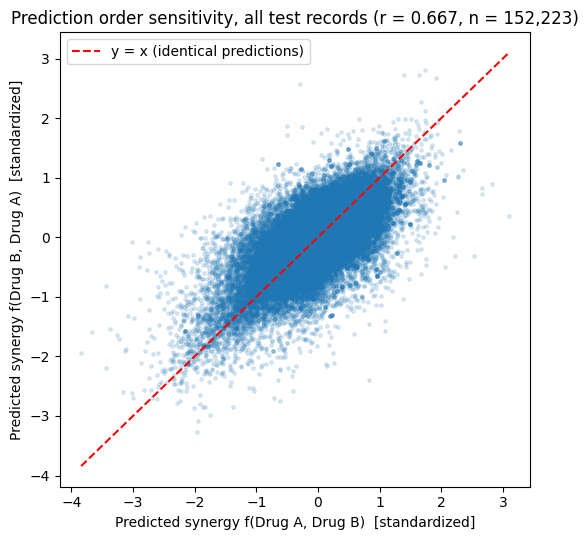

Pooled correlation over 152,223 test evaluations: r = 0.667

Saved -> /content/drive/MyDrive/DualGATSynergy/results_reproduced/order_sensitivity


In [ ]:
# ===== Cell 13: Table 10 and Figure 3 from this run (compare with Cell 3) =====
if RUN_HEAVY:
    paths = sorted(RUN_DIR.glob("order_sensitivity_fold*.csv"))
    if not paths:
        print(f"No finished folds in {RUN_DIR} (missing checkpoints?). Table 10 from our saved results: Cell 3.")
    else:
        this_run = pd.concat([pd.read_csv(p) for p in paths], ignore_index=True).sort_values("fold")
        main_results = pd.read_csv(MAIN_RESULTS) if MAIN_RESULTS.exists() else None
        print(f"{len(this_run)} of 5 folds found in {RUN_DIR}\n")
        summarize_order_sensitivity(this_run, main_results)
        this_run.to_csv(RUN_DIR / "order_sensitivity_summary.csv", index=False)      # never touches the reported results in results/
        plot_order_sensitivity([preds_path(int(k)) for k in this_run["fold"]], out_png=RUN_DIR / "order_sensitivity_all_folds.png")
        print(f"\nSaved -> {RUN_DIR}")